<a href="https://colab.research.google.com/github/Sangbartika-c/Phishing-Website-Detection/blob/main/Phishing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_PATH = Path("Phishing_Legitimate_full.csv")
if not DATA_PATH.exists():
    # Also works when run in the original uploaded-file environment.
    DATA_PATH = Path("/mnt/data/Phishing_Legitimate_full.csv")

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:\n", df.dtypes.value_counts())
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Dataset shape: (10000, 50)


,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,...,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,CLASS_LABEL
0,1,3,1,5,72,0,0,0,0,0,...,0,0,1,1,0,1,1,-1,1,1
1,2,3,1,3,144,0,0,0,0,2,...,0,0,0,1,-1,1,1,1,1,1
2,3,3,1,2,58,0,0,0,0,0,...,0,0,0,1,0,-1,1,-1,0,1
3,4,3,1,6,79,1,0,0,0,0,...,0,0,0,1,-1,1,1,1,-1,1
4,5,3,0,4,46,0,0,0,0,0,...,1,0,0,1,1,-1,0,-1,-1,1



Data types:
 int64      47
float64     3
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


labels

In [2]:
import pandas as pd

df = pd.read_csv("Phishing_Legitimate_full.csv")

# Define label meanings
label_mapping = {
    0: "Phishing Website",
    1: "Legitimate Website"
}

# Display label meanings
print("Class Label Meaning:")
for label, meaning in label_mapping.items():
    print(f"{label} = {meaning}")

# Count records in each class
print("\nClass Distribution:")

for label, count in df["CLASS_LABEL"].value_counts().sort_index().items():
    print(f"{label} ({label_mapping[label]}): {count} records")

Class Label Meaning:
0 = Phishing Website
1 = Legitimate Website

Class Distribution:
0 (Phishing Website): 5000 records
1 (Legitimate Website): 5000 records


Data quality and descriptive statistics

In [3]:
display(df.describe(include="all").T)
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("missing_count").to_frame())

,count,mean,std,min,25%,50%,75%,max
id,10000.0,5000.500000,2886.895680,1.0,2500.750000,5000.500000,7500.250000,10000.0
NumDots,10000.0,2.445100,1.346836,1.0,2.000000,2.000000,3.000000,21.0
SubdomainLevel,10000.0,0.586800,0.751214,0.0,0.000000,1.000000,1.000000,14.0
PathLevel,10000.0,3.300300,1.863241,0.0,2.000000,3.000000,4.000000,18.0
UrlLength,10000.0,70.264100,33.369877,12.0,48.000000,62.000000,84.000000,253.0
NumDash,10000.0,1.818000,3.106258,0.0,0.000000,0.000000,2.000000,55.0
NumDashInHostname,10000.0,0.138900,0.545744,0.0,0.000000,0.000000,0.000000,9.0
AtSymbol,10000.0,0.000300,0.017319,0.0,0.000000,0.000000,0.000000,1.0
TildeSymbol,10000.0,0.013100,0.113709,0.0,0.000000,0.000000,0.000000,1.0
NumUnderscore,10000.0,0.323200,1.114660,0.0,0.000000,0.000000,0.000000,18.0


,missing_count


Target distribution

,count
CLASS_LABEL,
0,5000
1,5000


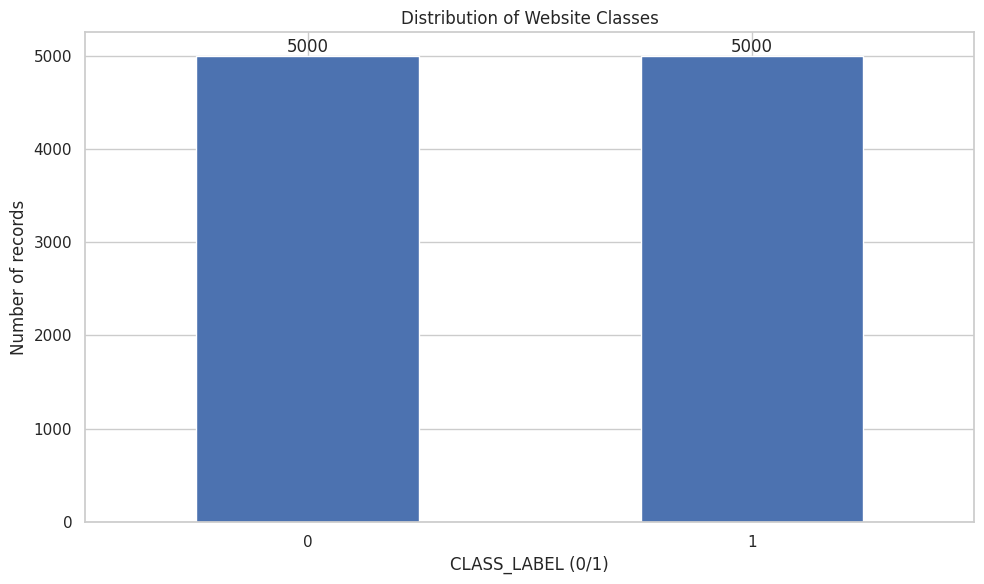

In [4]:
target_counts = df["CLASS_LABEL"].value_counts().sort_index()
display(target_counts.rename("count").to_frame())
ax = target_counts.plot(kind="bar", rot=0)
ax.set(title="Distribution of Website Classes", xlabel="CLASS_LABEL (0/1)", ylabel="Number of records")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

Feature distributions and outlier patterns

,mean,std,min,median,max
NumDots,2.445100,1.346836,1.0,2.000000,21.0
SubdomainLevel,0.586800,0.751214,0.0,1.000000,14.0
PathLevel,3.300300,1.863241,0.0,3.000000,18.0
UrlLength,70.264100,33.369877,12.0,62.000000,253.0
NumDash,1.818000,3.106258,0.0,0.000000,55.0
NumDashInHostname,0.138900,0.545744,0.0,0.000000,9.0
AtSymbol,0.000300,0.017319,0.0,0.000000,1.0
TildeSymbol,0.013100,0.113709,0.0,0.000000,1.0
NumUnderscore,0.323200,1.114660,0.0,0.000000,18.0
NumPercent,0.073800,0.622248,0.0,0.000000,19.0


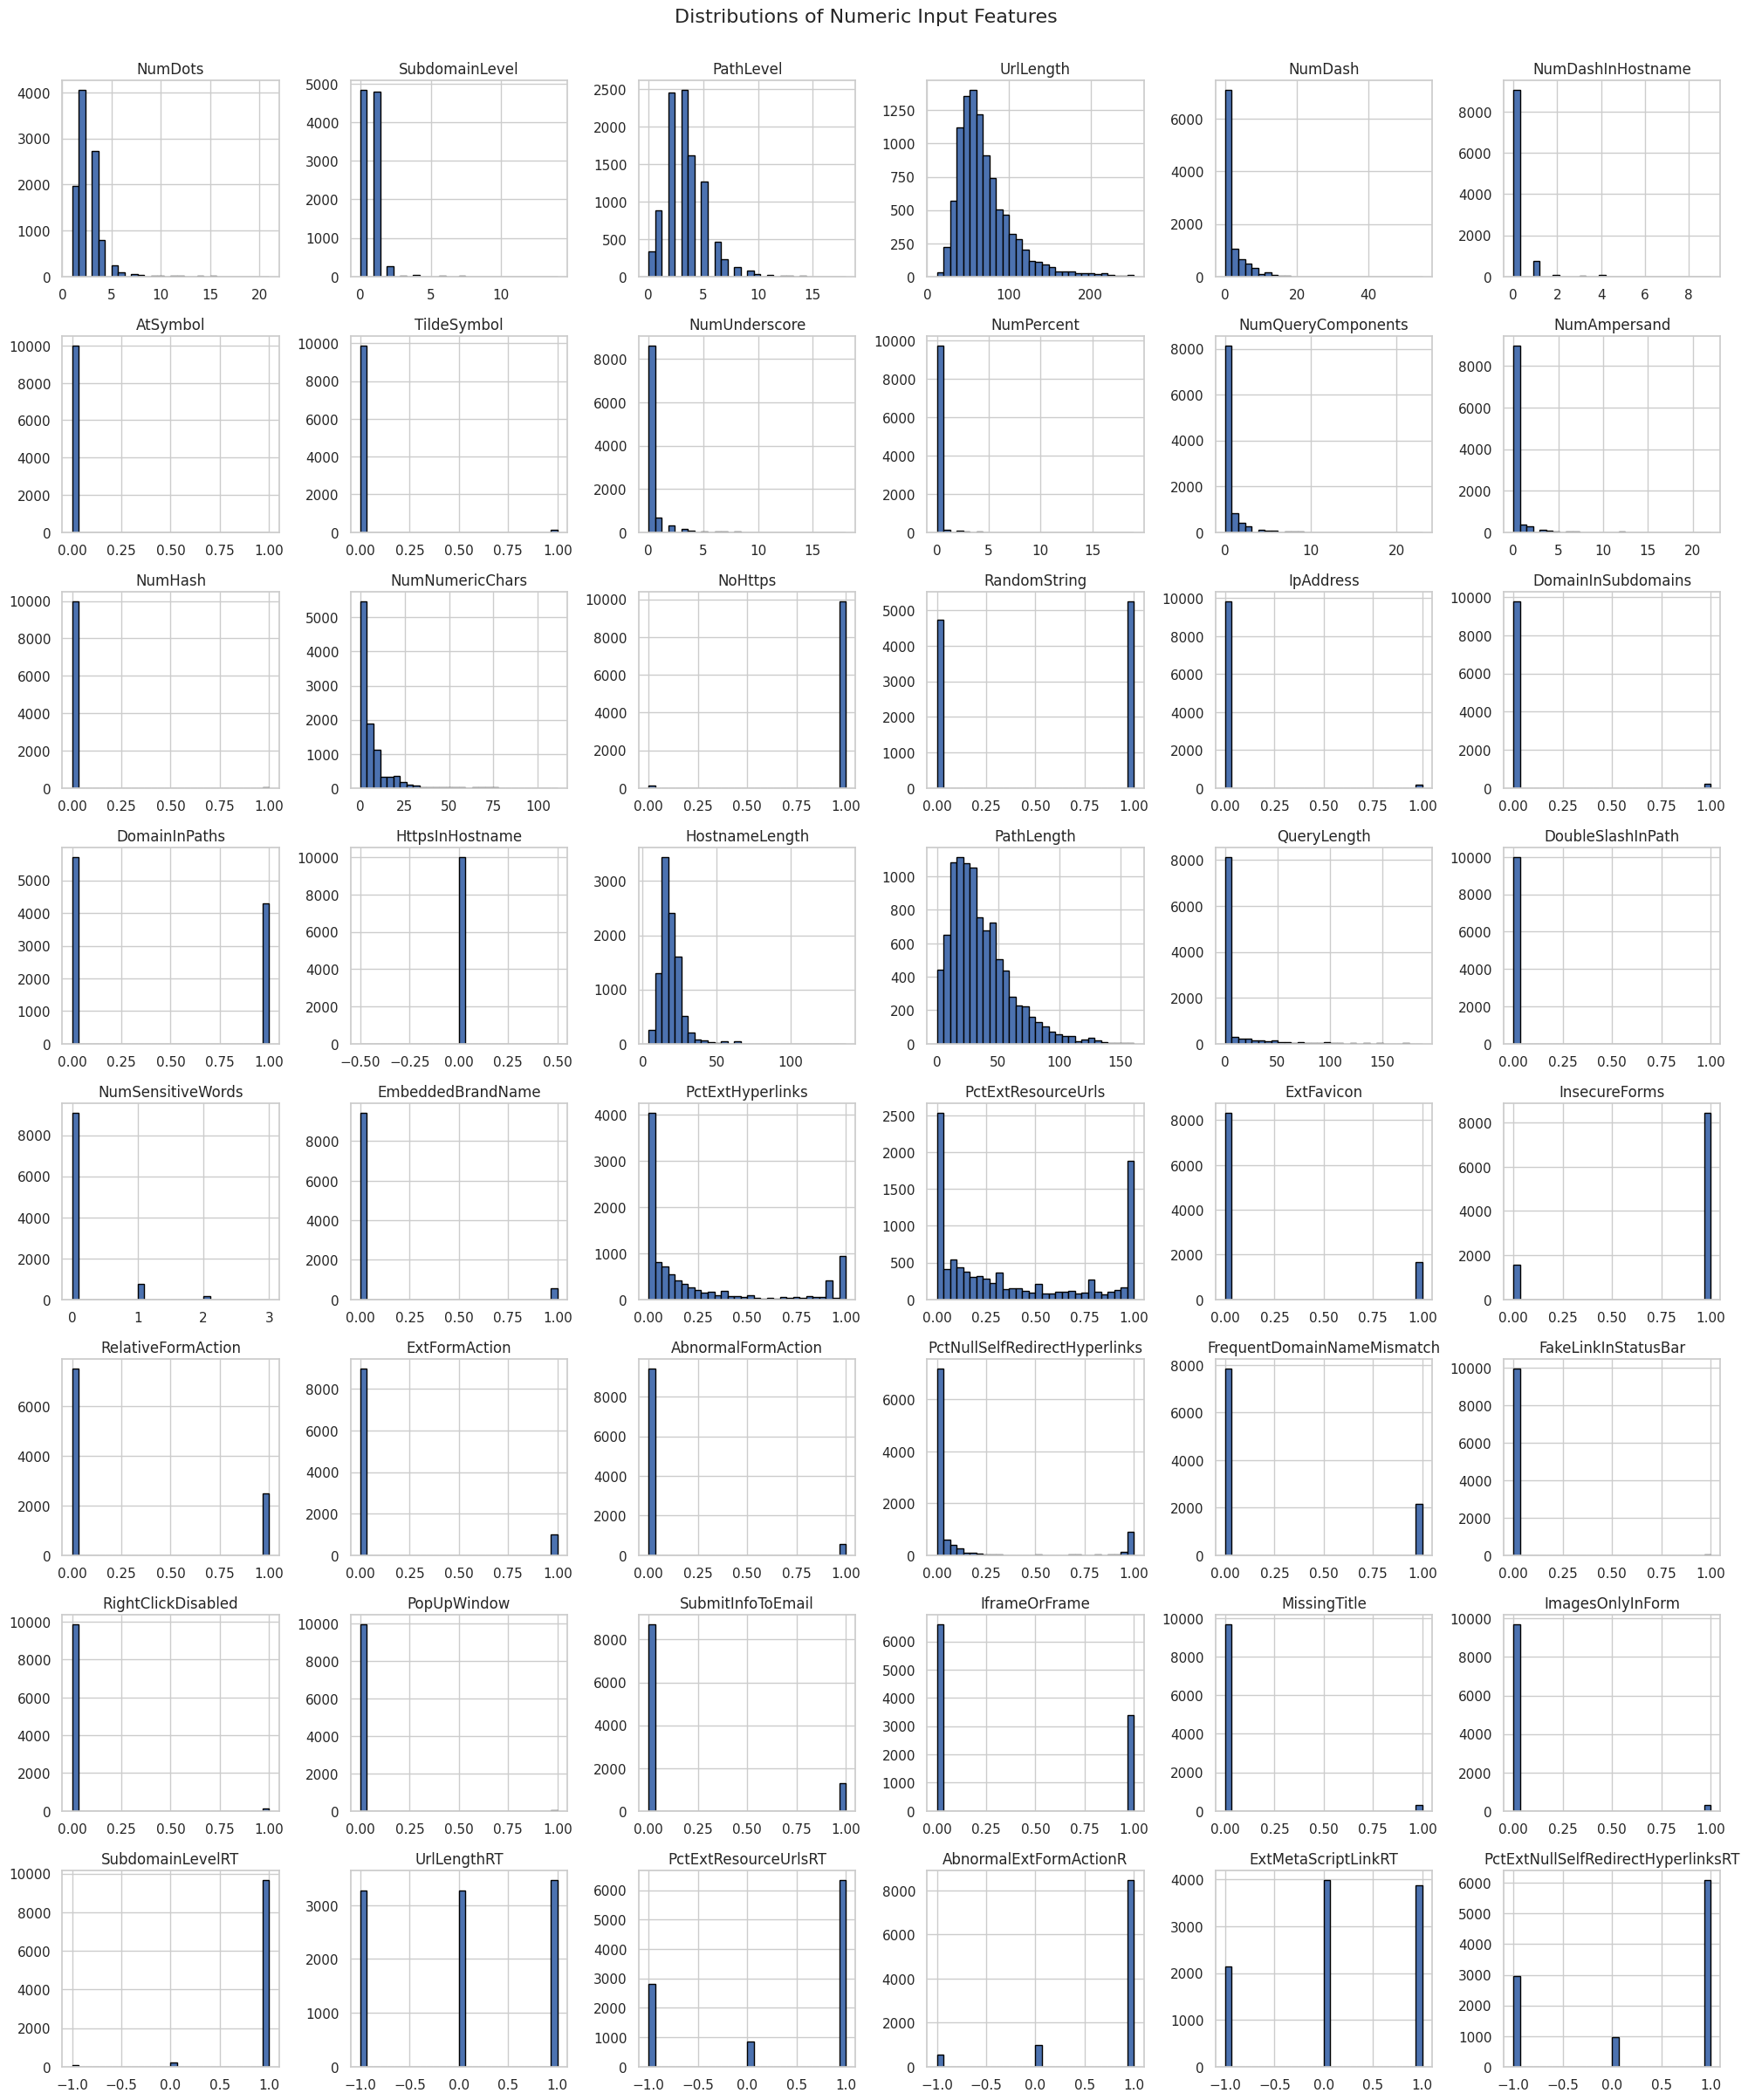

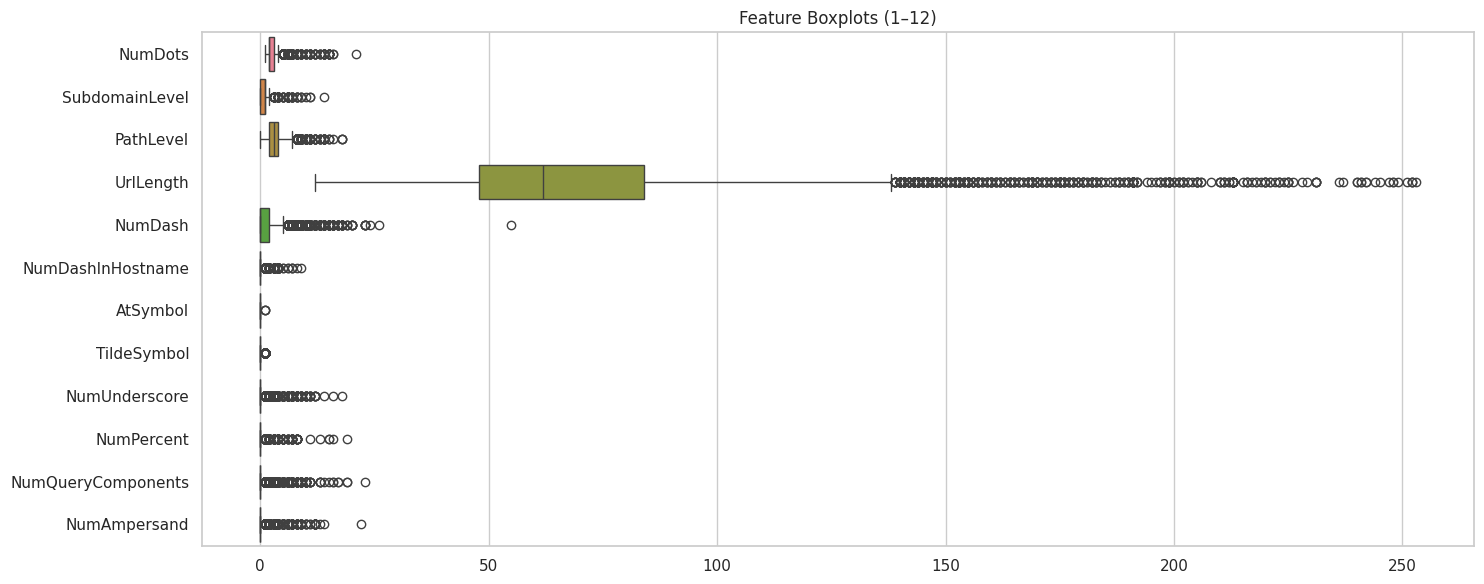

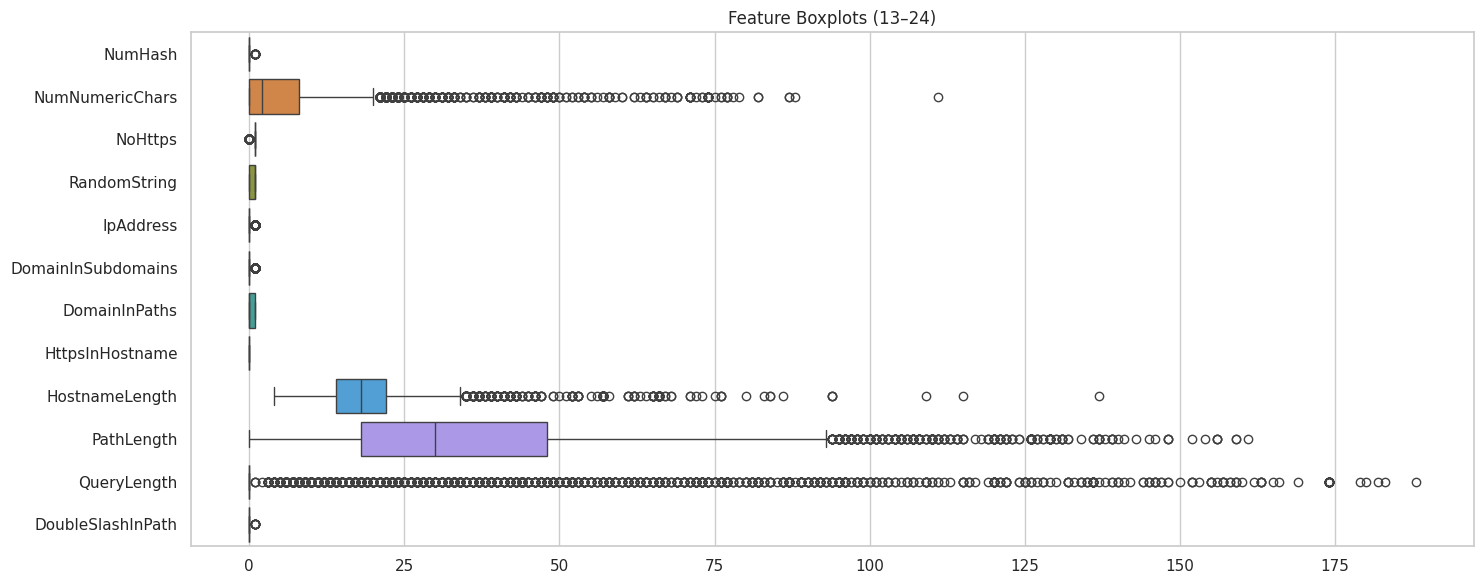

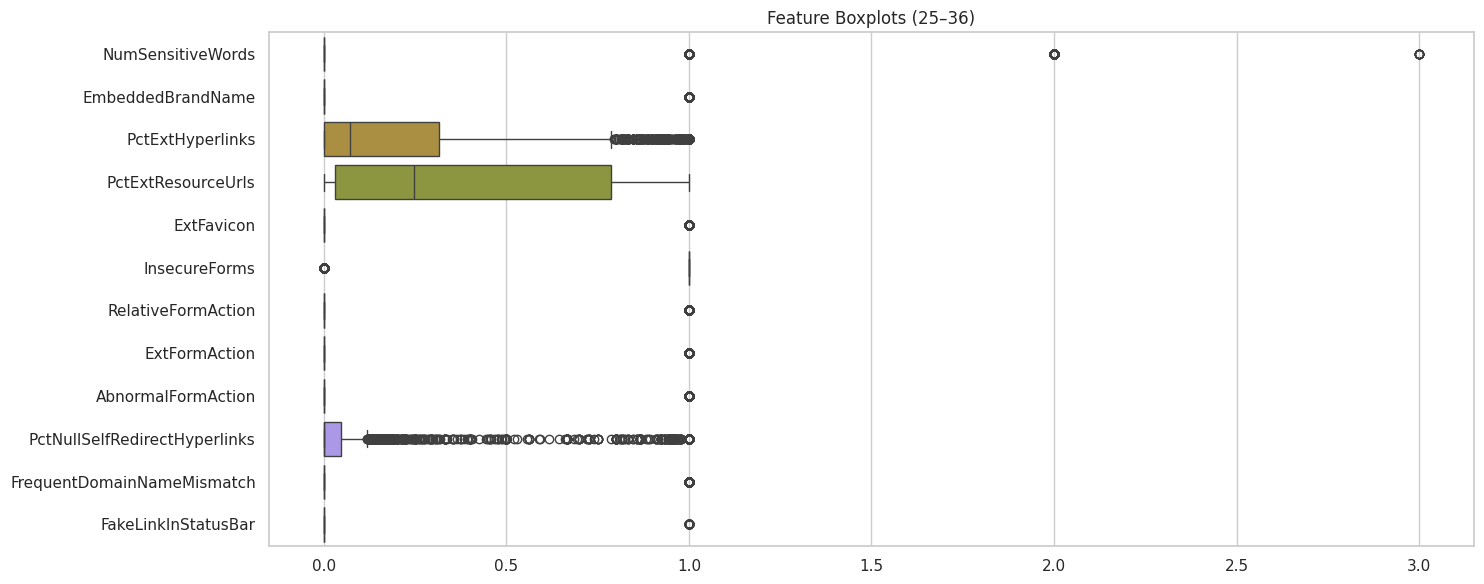

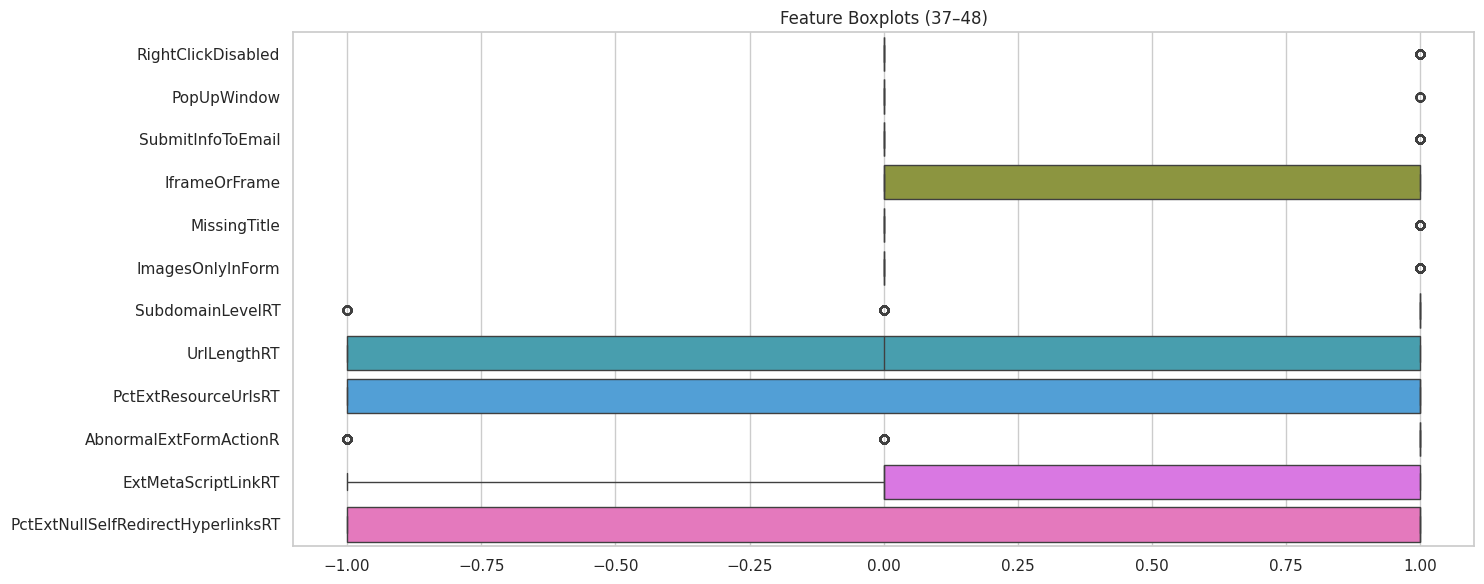

In [5]:
# Exclude identifier and target from exploratory feature plots.
feature_cols_all = [c for c in df.select_dtypes(include=np.number).columns
                    if c not in ["id", "CLASS_LABEL"]]
display(df[feature_cols_all].agg(["mean", "std", "min", "median", "max"]).T)

# Histograms: compact small-multiple view of all numerical predictors.
df[feature_cols_all].hist(figsize=(20, 24), bins=30, layout=(8, 6), edgecolor="black")
plt.suptitle("Distributions of Numeric Input Features", y=1.002, fontsize=16)
plt.tight_layout()
plt.show()

# Boxplots in batches so the feature names remain readable.
for start in range(0, len(feature_cols_all), 12):
    subset = feature_cols_all[start:start+12]
    plt.figure(figsize=(15, 6))
    sns.boxplot(data=df[subset], orient="h")
    plt.title(f"Feature Boxplots ({start+1}–{start+len(subset)})")
    plt.tight_layout()
    plt.show()

Class-wise feature patterns

CLASS_LABEL,0,1
NumDots,2.049000,2.841200
SubdomainLevel,0.554400,0.619200
PathLevel,2.872800,3.727800
UrlLength,72.749800,67.778400
NumDash,2.974200,0.661800
NumDashInHostname,0.056800,0.221000
AtSymbol,0.000600,0.000000
TildeSymbol,0.002200,0.024000
NumUnderscore,0.433400,0.213000
NumPercent,0.116400,0.031200


,class1_minus_class0_mean
UrlLength,-4.971400
QueryLength,-3.915400
PathLength,-3.743400
HostnameLength,2.745800
NumDash,-2.312400
PctExtNullSelfRedirectHyperlinksRT,-0.970600
PathLevel,0.855000
NumDots,0.792200
NumQueryComponents,-0.396400
FrequentDomainNameMismatch,0.381400


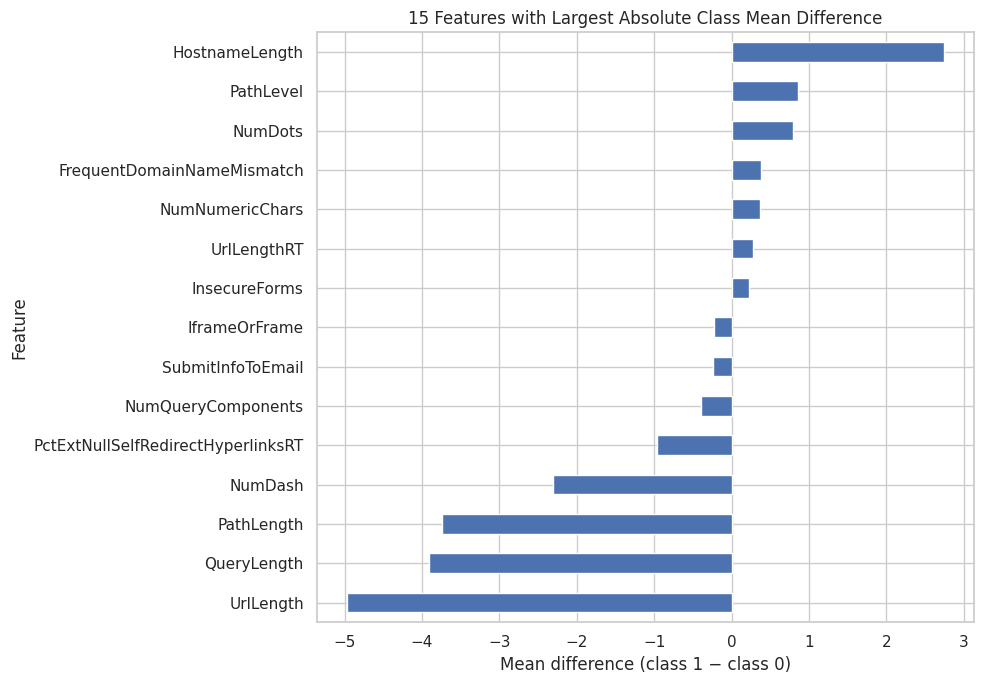

In [6]:
# Compare class means and medians; this is descriptive, not causal.
class_summary = df.groupby("CLASS_LABEL")[feature_cols_all].mean().T
display(class_summary)
mean_diff = (class_summary[1] - class_summary[0]).sort_values(
    key=lambda s: s.abs(), ascending=False
)
display(mean_diff.rename("class1_minus_class0_mean").to_frame())

top_diff = mean_diff.head(15).sort_values()
ax = top_diff.plot(kind="barh", figsize=(10, 7))
ax.set(title="15 Features with Largest Absolute Class Mean Difference",
       xlabel="Mean difference (class 1 − class 0)", ylabel="Feature")
plt.tight_layout()
plt.show()

Correlation analysis and ranked feature–target correlations

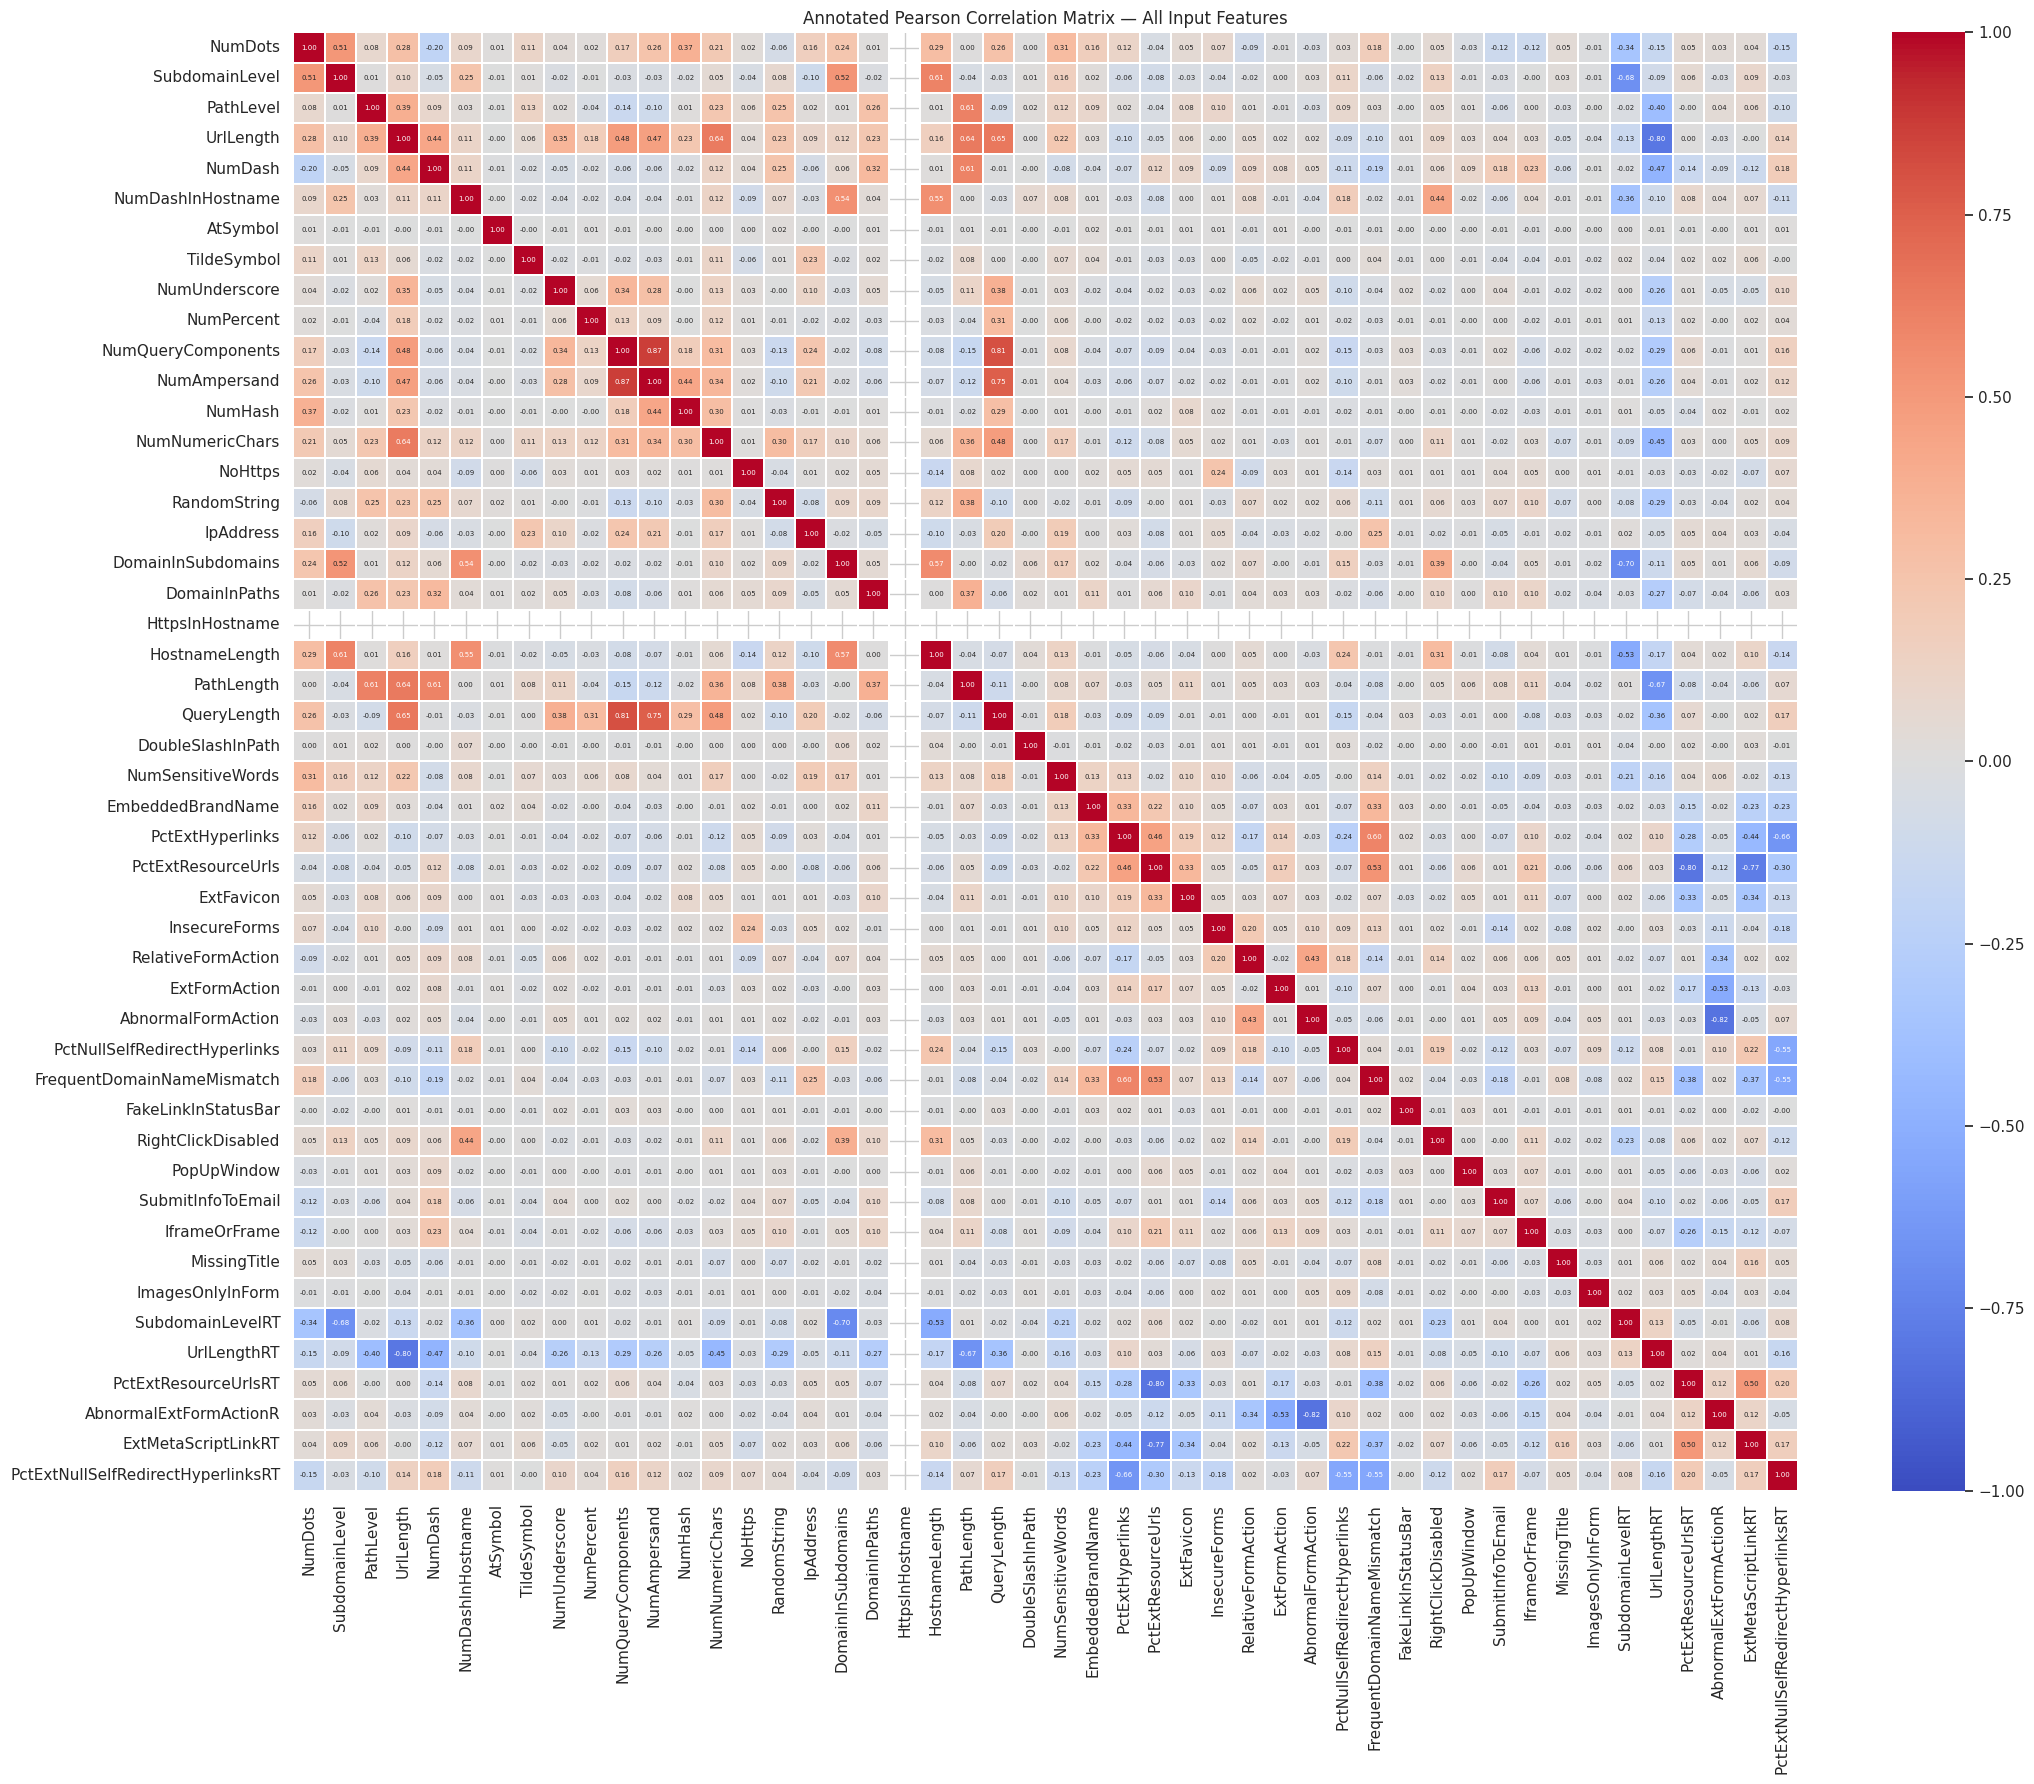

,correlation_with_CLASS_LABEL,absolute_correlation
PctExtNullSelfRedirectHyperlinksRT,-0.540545,0.540545
FrequentDomainNameMismatch,0.463956,0.463956
NumDash,-0.372235,0.372235
SubmitInfoToEmail,-0.357635,0.357635
PctNullSelfRedirectHyperlinks,0.342806,0.342806
InsecureForms,0.316380,0.316380
NumDots,0.294111,0.294111
PctExtHyperlinks,0.259728,0.259728
NumSensitiveWords,0.255208,0.255208
IframeOrFrame,-0.235233,0.235233


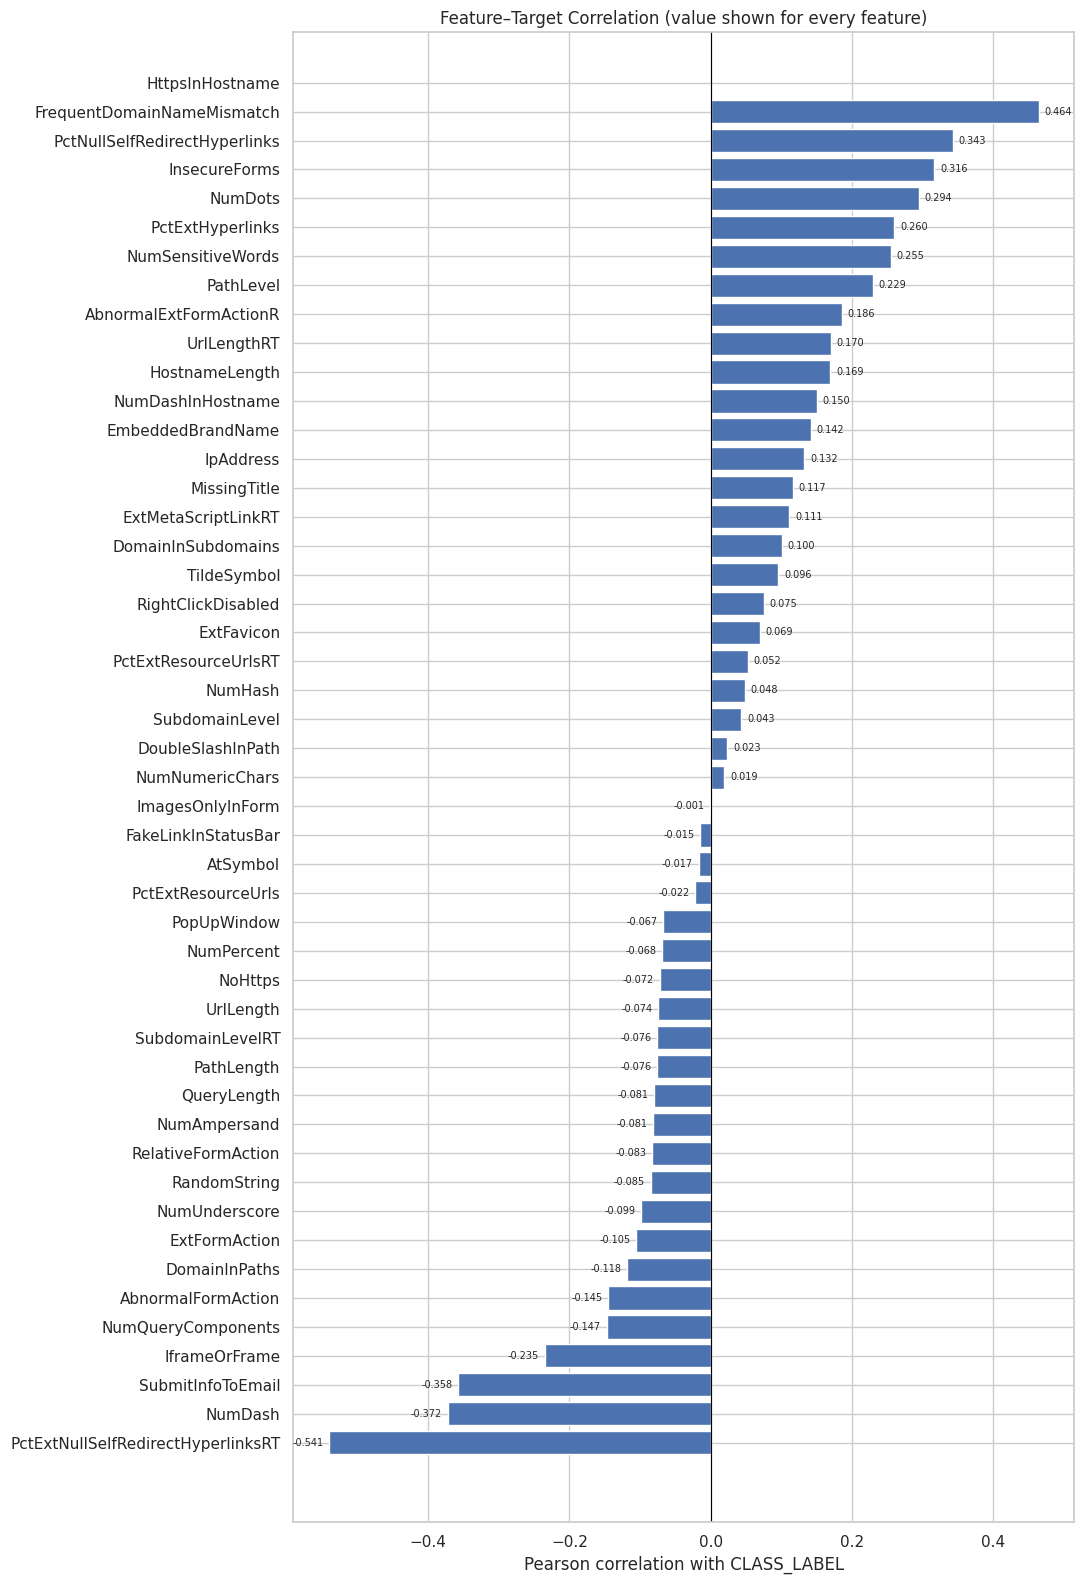

In [7]:
# Pearson correlation among predictors; id is excluded.
X_corr = df[feature_cols_all]
corr = X_corr.corr()
plt.figure(figsize=(22, 18))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 5}, linewidths=0.15)
plt.title("Annotated Pearson Correlation Matrix — All Input Features")
plt.tight_layout()
plt.show()

# Correlation of each predictor with the binary target, sorted by absolute magnitude.
target_corr = df[feature_cols_all + ["CLASS_LABEL"]].corr(numeric_only=True)["CLASS_LABEL"].drop("CLASS_LABEL")
target_corr_ranked = target_corr.rename("correlation_with_CLASS_LABEL").to_frame()
target_corr_ranked["absolute_correlation"] = target_corr_ranked["correlation_with_CLASS_LABEL"].abs()
target_corr_ranked = target_corr_ranked.sort_values("absolute_correlation", ascending=False)
display(target_corr_ranked)
target_corr_ranked.to_csv("feature_target_correlation_ranking.csv")

plot_corr = target_corr_ranked.sort_values("correlation_with_CLASS_LABEL")
plt.figure(figsize=(11, 16))
bars = plt.barh(plot_corr.index, plot_corr["correlation_with_CLASS_LABEL"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with CLASS_LABEL")
plt.title("Feature–Target Correlation (value shown for every feature)")
for bar, val in zip(bars, plot_corr["correlation_with_CLASS_LABEL"]):
    offset = 0.008 if val >= 0 else -0.008
    plt.text(val + offset, bar.get_y()+bar.get_height()/2, f"{val:.3f}",
             va="center", ha="left" if val >= 0 else "right", fontsize=7)
plt.tight_layout()
plt.show()

Preprocessing and train/test split

In [8]:
# Remove exact duplicate rows if present, then separate target.
data = df.drop_duplicates().copy()
y = data["CLASS_LABEL"].astype(int)
drop_cols = ["CLASS_LABEL"] + [c for c in data.columns if c.strip().lower() in ["id", "index", "unnamed: 0"]]
X = data.drop(columns=drop_cols).select_dtypes(include=np.number)

print("Predictor count:", X.shape[1])
print("Class counts:\n", y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Predictor count: 48
Class counts:
 CLASS_LABEL
0    5000
1    5000
Name: count, dtype: int64
Train: (8000, 48) Test: (2000, 48)


PCA for dimensionality reduction

Components for >=95% variance: 34 of 48
Components for >=99% variance: 41 of 48
Variance retained by first 34 components: 0.9530


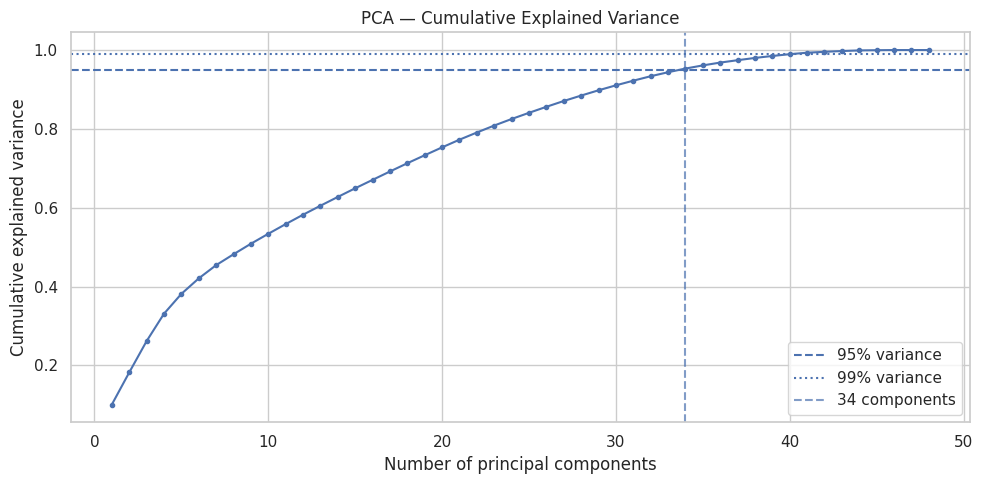

PCA train shape: (8000, 34) | PCA test shape: (2000, 34)


In [9]:
# Fit scaler and PCA only on training data to prevent test-data leakage.
pca_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=RANDOM_STATE))
])
pca_pipe.fit(X_train)
cum_var = np.cumsum(pca_pipe.named_steps["pca"].explained_variance_ratio_)
n95 = int(np.searchsorted(cum_var, 0.95) + 1)
n99 = int(np.searchsorted(cum_var, 0.99) + 1)
print(f"Components for >=95% variance: {n95} of {X.shape[1]}")
print(f"Components for >=99% variance: {n99} of {X.shape[1]}")
print(f"Variance retained by first {n95} components: {cum_var[n95-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(cum_var)+1), cum_var, marker="o", markersize=3)
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.axhline(0.99, linestyle=":", label="99% variance")
plt.axvline(n95, linestyle="--", alpha=.7, label=f"{n95} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

# PCA transformed datasets for optional downstream use.
pca_95 = PCA(n_components=0.95, random_state=RANDOM_STATE)
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)
print("PCA train shape:", X_train_pca.shape, "| PCA test shape:", X_test_pca.shape)

Baseline classification models (before tuning)

In [10]:
baseline_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE)
}

baseline_fitted = {}
baseline_predictions = {}
baseline_rows = []
baseline_reports = {}

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    baseline_fitted[name] = model
    baseline_predictions[name] = pred
    baseline_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })
    baseline_reports[name] = classification_report(y_test, pred, output_dict=True, zero_division=0)
    print(f"\n===== {name}: BEFORE TUNING =====")
    print(classification_report(y_test, pred, digits=4, zero_division=0))

baseline_results = pd.DataFrame(baseline_rows).sort_values("F1_macro", ascending=False)
display(baseline_results.round(4))
baseline_results.to_csv("baseline_model_comparison.csv", index=False)


===== Logistic Regression: BEFORE TUNING =====
              precision    recall  f1-score   support

           0     0.9593    0.9440    0.9516      1000
           1     0.9449    0.9600    0.9524      1000

    accuracy                         0.9520      2000
   macro avg     0.9521    0.9520    0.9520      2000
weighted avg     0.9521    0.9520    0.9520      2000


===== Decision Tree: BEFORE TUNING =====
              precision    recall  f1-score   support

           0     0.9668    0.9610    0.9639      1000
           1     0.9612    0.9670    0.9641      1000

    accuracy                         0.9640      2000
   macro avg     0.9640    0.9640    0.9640      2000
weighted avg     0.9640    0.9640    0.9640      2000


===== Random Forest: BEFORE TUNING =====
              precision    recall  f1-score   support

           0     0.9831    0.9870    0.9850      1000
           1     0.9869    0.9830    0.9850      1000

    accuracy                         0.9850      2

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
4,Hist Gradient Boosting,0.9880,0.9880,0.9880,0.9880
2,Random Forest,0.9850,0.9850,0.9850,0.9850
3,Extra Trees,0.9845,0.9846,0.9845,0.9845
1,Decision Tree,0.9640,0.9640,0.9640,0.9640
0,Logistic Regression,0.9520,0.9521,0.9520,0.9520


Hyperparameter tuning with RandomizedSearchCV

In [11]:
# Search is conducted only on training data with stratified 2-fold CV.
# n_iter can be increased for a more exhaustive search (at higher runtime cost).
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["liblinear", "lbfgs"],
        "model__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "criterion": ["gini", "entropy", "log_loss"],
        "max_depth": [None, 5, 10, 20, 30],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 4, 8],
        "class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "n_estimators": [80, 120, 180],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.5],
        "class_weight": [None, "balanced"]
    },
    "Extra Trees": {
        "n_estimators": [80, 120, 180],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.5],
        "class_weight": [None, "balanced"]
    },
    "Hist Gradient Boosting": {
        "learning_rate": [0.03, 0.05, 0.1, 0.2],
        "max_iter": [100, 150, 250],
        "max_leaf_nodes": [15, 31, 63],
        "l2_regularization": [0.0, 0.1, 1.0]
    }
}

tuned_estimators = {}
tuned_predictions = {}
tuned_rows = []
tuned_reports = {}
best_params = {}

for name, estimator in baseline_models.items():
    print(f"\nTuning {name} ...")
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=search_spaces[name],
        n_iter=4,
        scoring="f1_macro",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=1,
        refit=True,
        verbose=0
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_
    pred = best_model.predict(X_test)
    tuned_estimators[name] = best_model
    tuned_predictions[name] = pred
    best_params[name] = search.best_params_
    tuned_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Best_CV_F1_macro": search.best_score_
    })
    tuned_reports[name] = classification_report(y_test, pred, output_dict=True, zero_division=0)
    print("Best CV macro-F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print(f"===== {name}: AFTER TUNING =====")
    print(classification_report(y_test, pred, digits=4, zero_division=0))

tuned_results = pd.DataFrame(tuned_rows).sort_values("F1_macro", ascending=False)
display(tuned_results.round(4))
tuned_results.to_csv("tuned_model_comparison.csv", index=False)
with open("best_hyperparameters.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)


Tuning Logistic Regression ...
Best CV macro-F1: 0.9425
Best parameters: {'model__solver': 'lbfgs', 'model__class_weight': 'balanced', 'model__C': 10}
===== Logistic Regression: AFTER TUNING =====
              precision    recall  f1-score   support

           0     0.9603    0.9440    0.9521      1000
           1     0.9449    0.9610    0.9529      1000

    accuracy                         0.9525      2000
   macro avg     0.9526    0.9525    0.9525      2000
weighted avg     0.9526    0.9525    0.9525      2000


Tuning Decision Tree ...
Best CV macro-F1: 0.9591
Best parameters: {'min_samples_split': 20, 'min_samples_leaf': 1, 'max_depth': 10, 'criterion': 'log_loss', 'class_weight': 'balanced'}
===== Decision Tree: AFTER TUNING =====
              precision    recall  f1-score   support

           0     0.9555    0.9660    0.9607      1000
           1     0.9656    0.9550    0.9603      1000

    accuracy                         0.9605      2000
   macro avg     0.9606    0.9

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Best_CV_F1_macro
4,Hist Gradient Boosting,0.9815,0.9815,0.9815,0.9815,0.9779
2,Random Forest,0.9785,0.9786,0.9785,0.9785,0.9735
3,Extra Trees,0.9760,0.9762,0.9760,0.9760,0.9687
1,Decision Tree,0.9605,0.9606,0.9605,0.9605,0.9591
0,Logistic Regression,0.9525,0.9526,0.9525,0.9525,0.9425


Before-vs-after tuning comparison

,Model,Accuracy_before,Accuracy_after,F1_macro_before,F1_macro_after,Accuracy_change,F1_macro_change
0,Hist Gradient Boosting,0.9880,0.9815,0.9880,0.9815,-0.0065,-0.0065
1,Random Forest,0.9850,0.9785,0.9850,0.9785,-0.0065,-0.0065
2,Extra Trees,0.9845,0.9760,0.9845,0.9760,-0.0085,-0.0085
3,Decision Tree,0.9640,0.9605,0.9640,0.9605,-0.0035,-0.0035
4,Logistic Regression,0.9520,0.9525,0.9520,0.9525,0.0005,0.0005


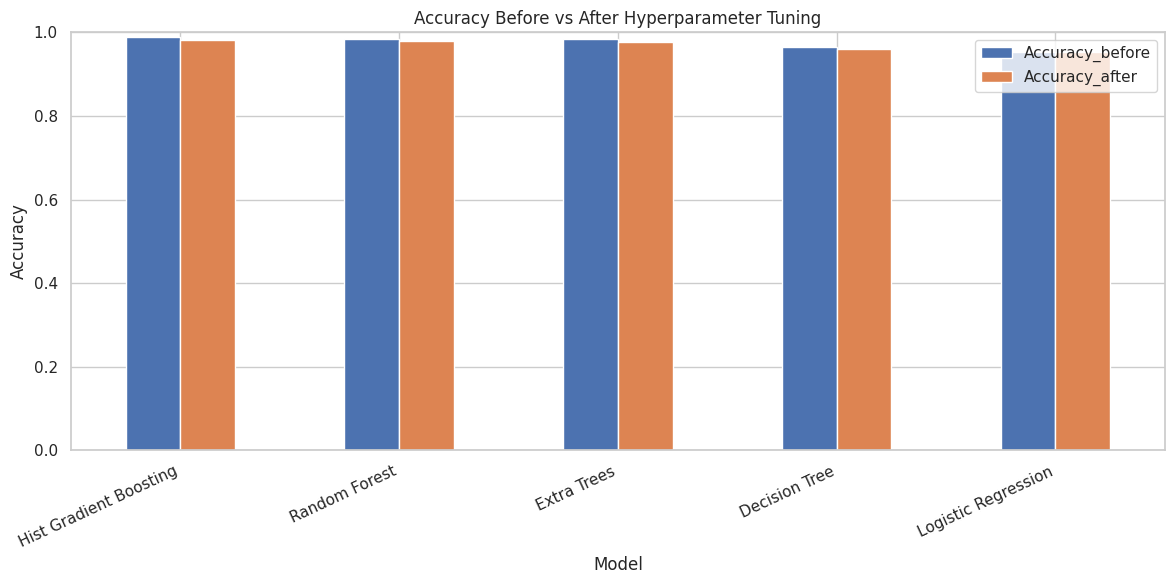

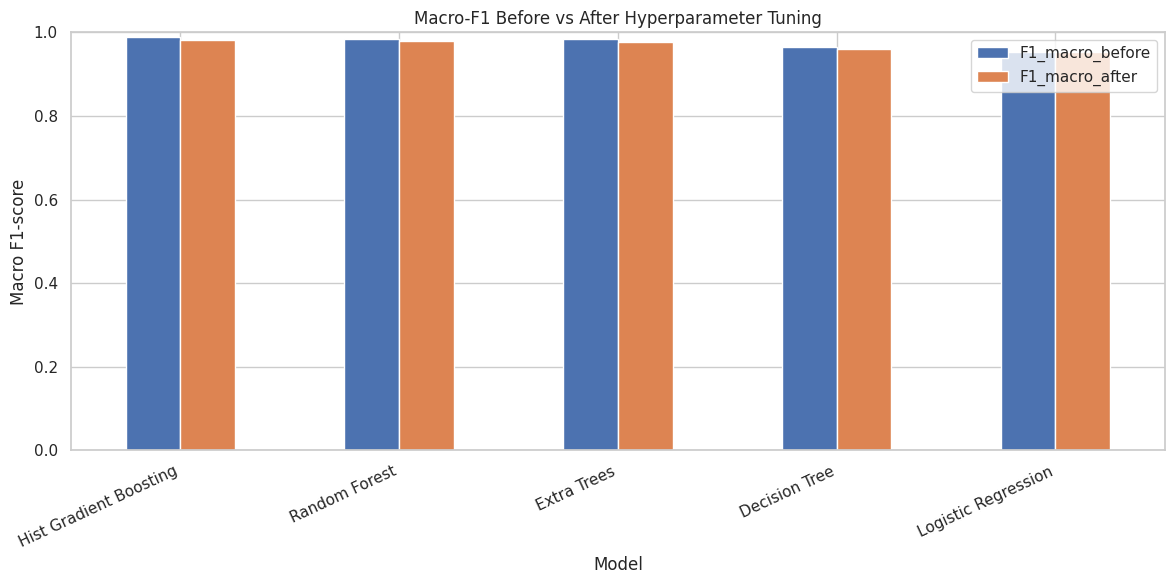

In [12]:
comparison = baseline_results.merge(
    tuned_results, on="Model", suffixes=("_before", "_after")
)
comparison["Accuracy_change"] = comparison["Accuracy_after"] - comparison["Accuracy_before"]
comparison["F1_macro_change"] = comparison["F1_macro_after"] - comparison["F1_macro_before"]
display(comparison[[
    "Model", "Accuracy_before", "Accuracy_after",
    "F1_macro_before", "F1_macro_after", "Accuracy_change", "F1_macro_change"
]].sort_values("F1_macro_after", ascending=False).round(4))
comparison.to_csv("before_after_tuning_comparison.csv", index=False)

ax = comparison.set_index("Model")[["Accuracy_before", "Accuracy_after"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
ax.set(title="Accuracy Before vs After Hyperparameter Tuning", ylabel="Accuracy")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

ax = comparison.set_index("Model")[["F1_macro_before", "F1_macro_after"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
ax.set(title="Macro-F1 Before vs After Hyperparameter Tuning", ylabel="Macro F1-score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Classification reports and confusion matrices after tuning


Logistic Regression — tuned classification report
              precision    recall  f1-score   support

           0     0.9603    0.9440    0.9521      1000
           1     0.9449    0.9610    0.9529      1000

    accuracy                         0.9525      2000
   macro avg     0.9526    0.9525    0.9525      2000
weighted avg     0.9526    0.9525    0.9525      2000



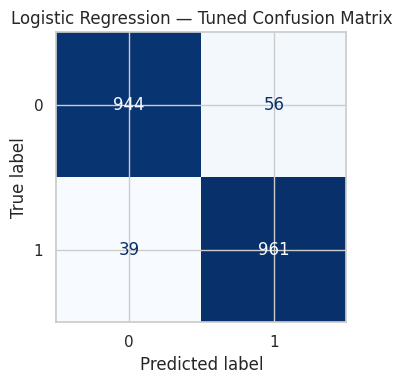


Decision Tree — tuned classification report
              precision    recall  f1-score   support

           0     0.9555    0.9660    0.9607      1000
           1     0.9656    0.9550    0.9603      1000

    accuracy                         0.9605      2000
   macro avg     0.9606    0.9605    0.9605      2000
weighted avg     0.9606    0.9605    0.9605      2000



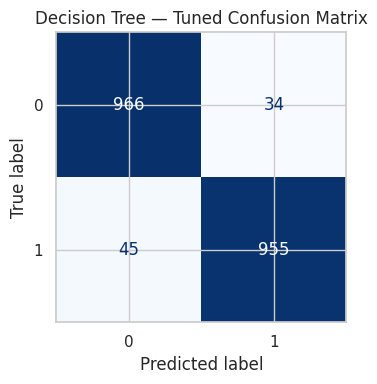


Random Forest — tuned classification report
              precision    recall  f1-score   support

           0     0.9724    0.9850    0.9786      1000
           1     0.9848    0.9720    0.9784      1000

    accuracy                         0.9785      2000
   macro avg     0.9786    0.9785    0.9785      2000
weighted avg     0.9786    0.9785    0.9785      2000



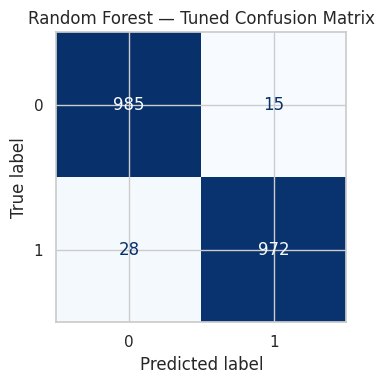


Extra Trees — tuned classification report
              precision    recall  f1-score   support

           0     0.9658    0.9870    0.9763      1000
           1     0.9867    0.9650    0.9757      1000

    accuracy                         0.9760      2000
   macro avg     0.9762    0.9760    0.9760      2000
weighted avg     0.9762    0.9760    0.9760      2000



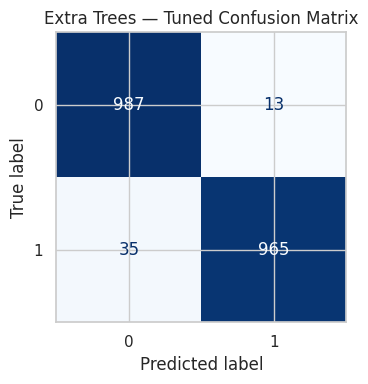


Hist Gradient Boosting — tuned classification report
              precision    recall  f1-score   support

           0     0.9801    0.9830    0.9815      1000
           1     0.9829    0.9800    0.9815      1000

    accuracy                         0.9815      2000
   macro avg     0.9815    0.9815    0.9815      2000
weighted avg     0.9815    0.9815    0.9815      2000



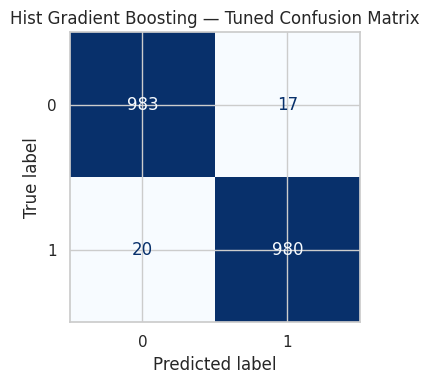

In [13]:
for name, pred in tuned_predictions.items():
    print(f"\n{name} — tuned classification report")
    print(classification_report(y_test, pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} — Tuned Confusion Matrix")
    plt.tight_layout()
    plt.show()

Feature importance from the best tuned tree model

In [14]:
best_name = tuned_results.iloc[0]["Model"]
best_estimator = tuned_estimators[best_name]
print("Best tuned model by test macro-F1:", best_name)

if hasattr(best_estimator, "feature_importances_"):
    importances = pd.Series(best_estimator.feature_importances_, index=X.columns).sort_values(ascending=False)
    display(importances.head(20).rename("importance").to_frame())
    importances.head(20).sort_values().plot(kind="barh", figsize=(10, 7))
    plt.title(f"Top 20 Feature Importances — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
elif hasattr(best_estimator, "named_steps") and hasattr(best_estimator.named_steps.get("model", None), "coef_"):
    coefs = pd.Series(np.abs(best_estimator.named_steps["model"].coef_[0]), index=X.columns).sort_values(ascending=False)
    display(coefs.head(20).rename("absolute_coefficient").to_frame())
    coefs.head(20).sort_values().plot(kind="barh", figsize=(10, 7))
    plt.title("Top 20 Features by Absolute Logistic Regression Coefficient")
    plt.tight_layout()
    plt.show()
else:
    print("This model does not expose built-in feature importance.")

Best tuned model by test macro-F1: Hist Gradient Boosting
This model does not expose built-in feature importance.


classification using PCA-reduced features

In [15]:
pca_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
original_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
for label, estimator in [("Logistic Regression — original features", original_lr),
                         ("Logistic Regression — PCA 95%", pca_lr)]:
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    print(label)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4),
          "Macro-F1:", round(f1_score(y_test, pred, average="macro"), 4))
    print(classification_report(y_test, pred, digits=4, zero_division=0))

Logistic Regression — original features
Accuracy: 0.952 Macro-F1: 0.952
              precision    recall  f1-score   support

           0     0.9593    0.9440    0.9516      1000
           1     0.9449    0.9600    0.9524      1000

    accuracy                         0.9520      2000
   macro avg     0.9521    0.9520    0.9520      2000
weighted avg     0.9521    0.9520    0.9520      2000

Logistic Regression — PCA 95%
Accuracy: 0.9385 Macro-F1: 0.9385
              precision    recall  f1-score   support

           0     0.9434    0.9330    0.9382      1000
           1     0.9337    0.9440    0.9388      1000

    accuracy                         0.9385      2000
   macro avg     0.9386    0.9385    0.9385      2000
weighted avg     0.9386    0.9385    0.9385      2000

